In [4]:
import numpy as np
import logging
from sklearn.datasets import make_regression, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, r2_score
from adaptivelasso.skcompat import MAPAdaptiveLasso

# Configure logging
logging.basicConfig(
    level=logging.INFO,  # Set log level to INFO
    format='%(asctime)s - %(levelname)s - %(message)s'
)
logger = logging.getLogger(__name__)

# Function to train and evaluate LassoCV
def train_evaluate_lasso(X_train, X_test, y_train, y_test):
    logger.info("Training LassoCV...")
    lasso = LassoCV(cv=5, random_state=42)
    lasso.fit(X_train, y_train)
    logger.info("LassoCV training completed.")
    
    logger.info("Evaluating LassoCV...")
    y_pred = lasso.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    logger.info(f"LassoCV evaluation completed. MSE: {mse:.4f}, R²: {r2:.4f}")
    return mse, r2

# Function to train and evaluate AdaptiveLasso
def train_evaluate_adaptive_lasso(X_train, X_test, y_train, y_test):
    logger.info("Training AdaptiveLasso...")
    adaptivelasso = MAPAdaptiveLasso(lam_prior='adaptive', lik='normal', max_iters=300, track=False)
    adaptivelasso.fit(X_train, y_train)
    logger.info("AdaptiveLasso training completed.")
    
    logger.info("Evaluating AdaptiveLasso...")
    y_pred = adaptivelasso.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    logger.info(f"AdaptiveLasso evaluation completed. MSE: {mse:.4f}, R²: {r2:.4f}")
    return mse, r2

# Function to compare both methods
def compare_lasso_methods(X, y, dataset_name):
    logger.info(f"Starting comparison for dataset: {dataset_name}")
    
    # Split data into train and test sets
    logger.info("Splitting data into train and test sets...")
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    logger.info("Data split completed.")
    
    # Train and evaluate LassoCV
    mse_lasso, r2_lasso = train_evaluate_lasso(X_train, X_test, y_train, y_test)

    # Train and evaluate AdaptiveLasso
    mse_adaptive, r2_adaptive = train_evaluate_adaptive_lasso(X_train, X_test, y_train, y_test)

    # Print results
    logger.info(f"Comparison results for dataset: {dataset_name}")
    logger.info(f"LassoCV - MSE: {mse_lasso:.4f}, R²: {r2_lasso:.4f}")
    logger.info(f"AdaptiveLasso - MSE: {mse_adaptive:.4f}, R²: {r2_adaptive:.4f}")

# Synthetic Dataset
logger.info("Generating synthetic dataset...")
X_synthetic, y_synthetic = make_regression(
    n_samples=1000, n_features=20, n_informative=5, noise=0.1, random_state=42
)
logger.info("Synthetic dataset generated.")
compare_lasso_methods(X_synthetic, y_synthetic, "Synthetic Dataset")

# Diabetes Dataset
logger.info("Loading diabetes dataset...")
diabetes = load_diabetes()
X_diabetes, y_diabetes = diabetes.data, diabetes.target
logger.info("Diabetes dataset loaded.")
compare_lasso_methods(X_diabetes, y_diabetes, "Diabetes Dataset")

2025-06-19 00:10:07,337 - INFO - Generating synthetic dataset...
2025-06-19 00:10:07,342 - INFO - Synthetic dataset generated.
2025-06-19 00:10:07,342 - INFO - Starting comparison for dataset: Synthetic Dataset
2025-06-19 00:10:07,342 - INFO - Splitting data into train and test sets...
2025-06-19 00:10:07,343 - INFO - Data split completed.
2025-06-19 00:10:07,343 - INFO - Training LassoCV...
2025-06-19 00:10:07,394 - INFO - LassoCV training completed.
2025-06-19 00:10:07,395 - INFO - Evaluating LassoCV...
2025-06-19 00:10:07,395 - INFO - LassoCV evaluation completed. MSE: 0.0489, R²: 1.0000
2025-06-19 00:10:07,395 - INFO - Training AdaptiveLasso...
INFO:2025-06-19 00:10:07,445:jax._src.xla_bridge:867: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/u543860/miniforge3/envs/arm_jax_env/bin/../lib/libtpu.so' (no such file), '/usr/lib

Testing max_iters=300, lr_pre=0.0005
  MSE: 5118.3298, R²: 0.0019
  Coefficients: [ 0.01918524  0.0024138   0.062953    0.04798551  0.01890018  0.01324998
 -0.04264017  0.04337942  0.05928212  0.03625515]
  Number of nonzero coefficients: 10


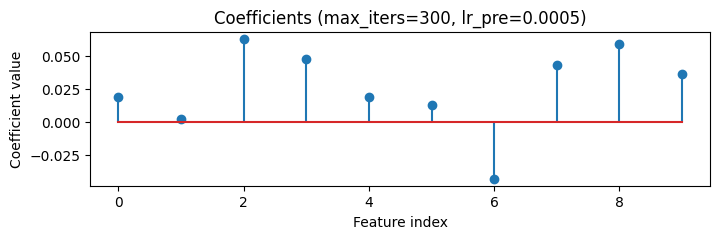

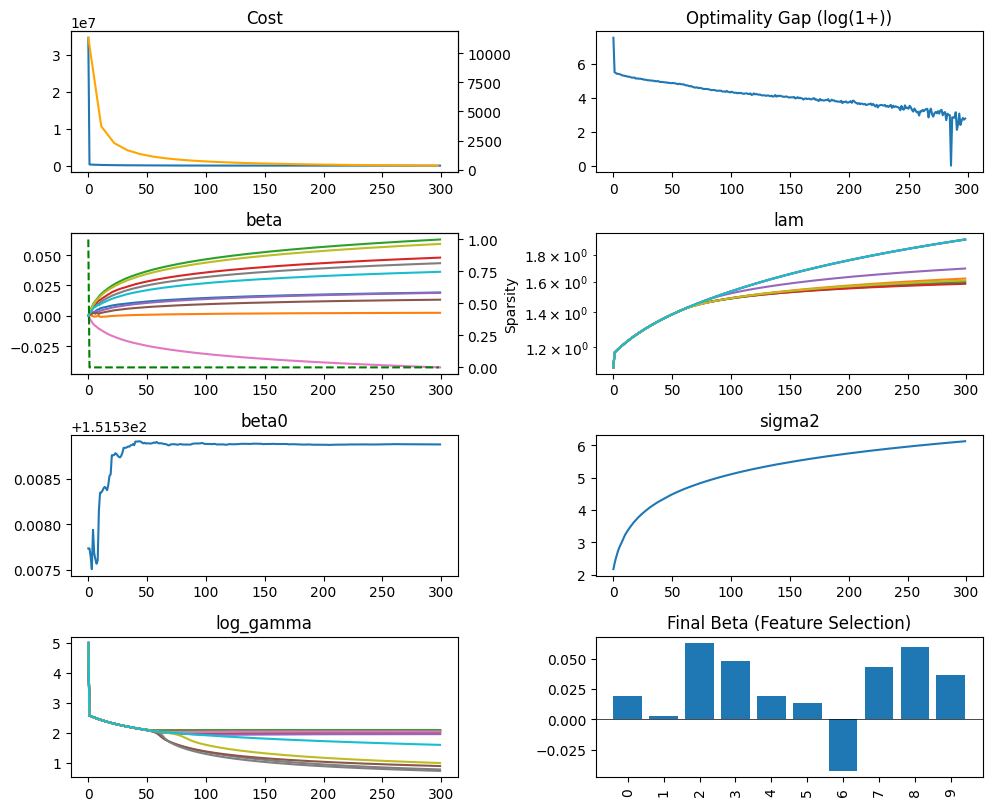

Testing max_iters=300, lr_pre=0.001
  MSE: 5113.2556, R²: 0.0029
  Coefficients: [ 0.02335011  0.00118151  0.07006171  0.05687272  0.02461911  0.01953484
 -0.05309339  0.05561711  0.0704563   0.04361995]
  Number of nonzero coefficients: 10


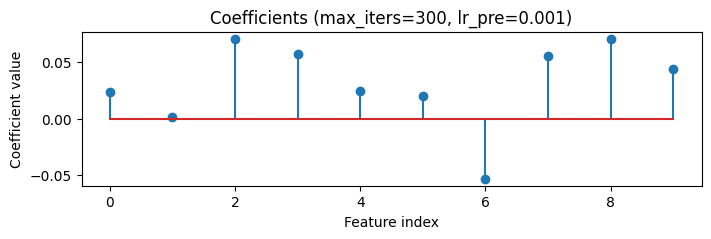

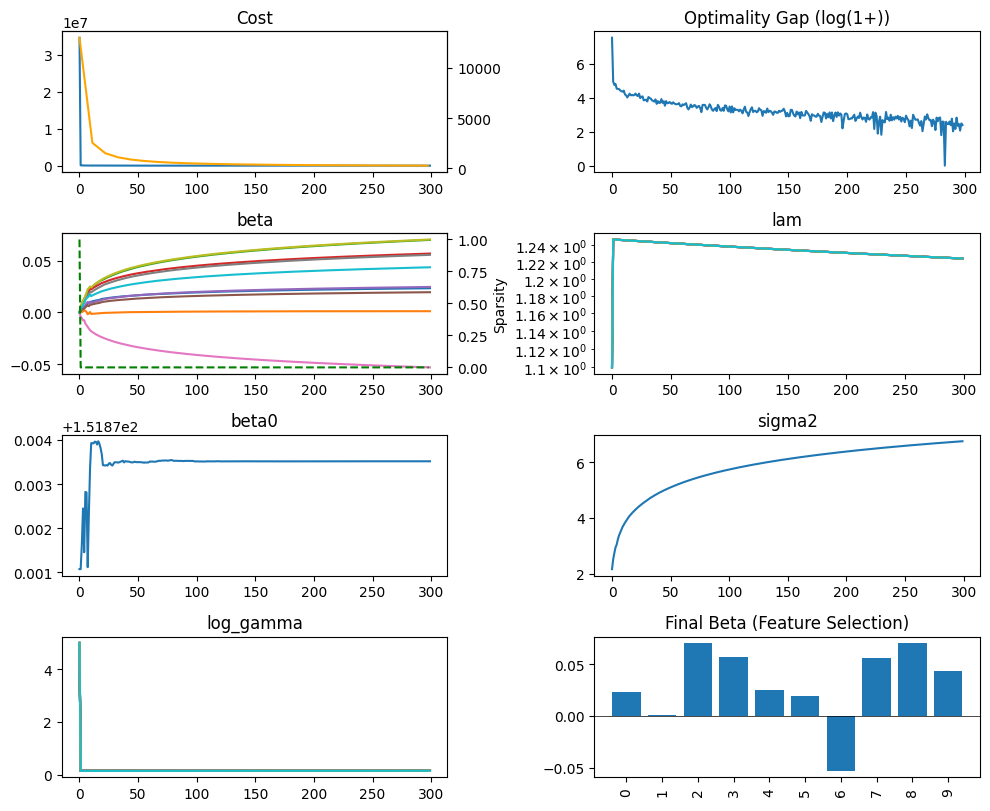

Testing max_iters=300, lr_pre=0.01
  MSE: 5116.1934, R²: 0.0023
  Coefficients: [ 0.05163701 -0.04333086  0.1370448   0.06162106  0.04533027  0.00890117
 -0.06417091  0.05277712  0.15117543  0.10723917]
  Number of nonzero coefficients: 10


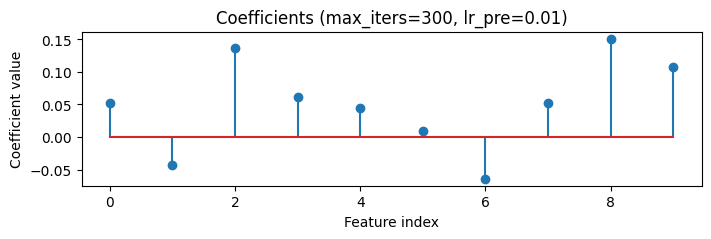

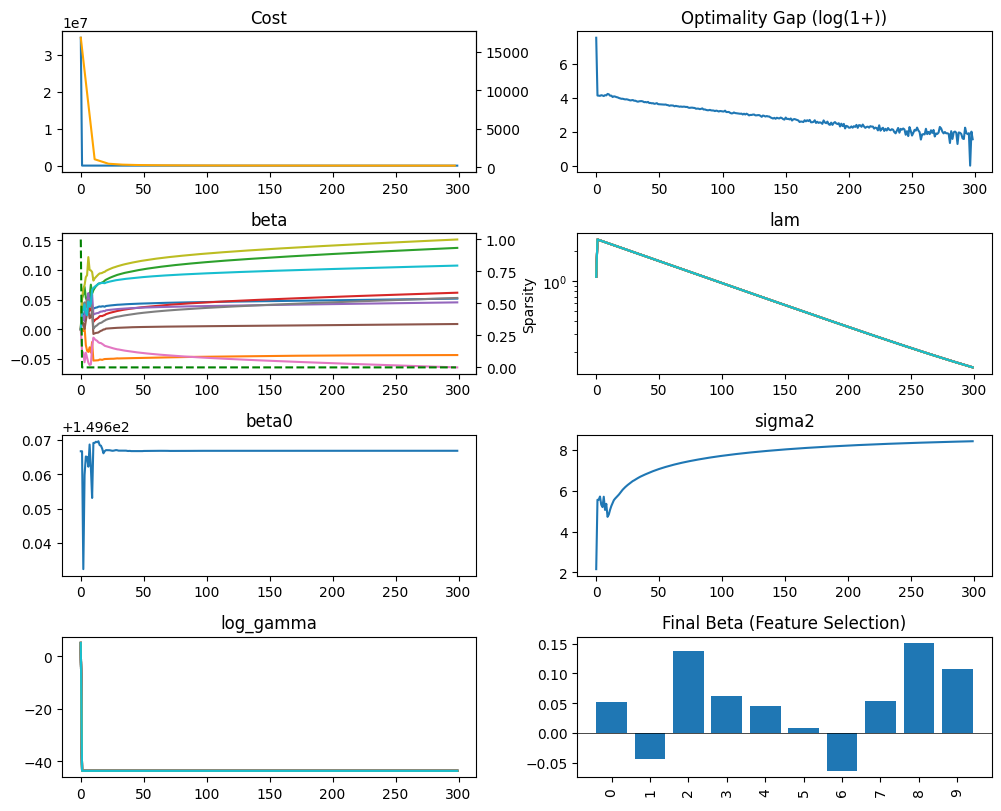

Testing max_iters=300, lr_pre=0.1
  MSE: 5025.2672, R²: 0.0200
  Coefficients: [ 0.66041122  0.15311927  0.28804176  1.12313136 -0.58329997 -0.69893601
 -0.50959492  0.0633585   0.34837125  0.08911811]
  Number of nonzero coefficients: 10


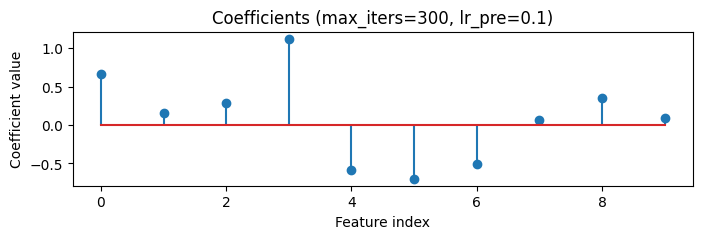

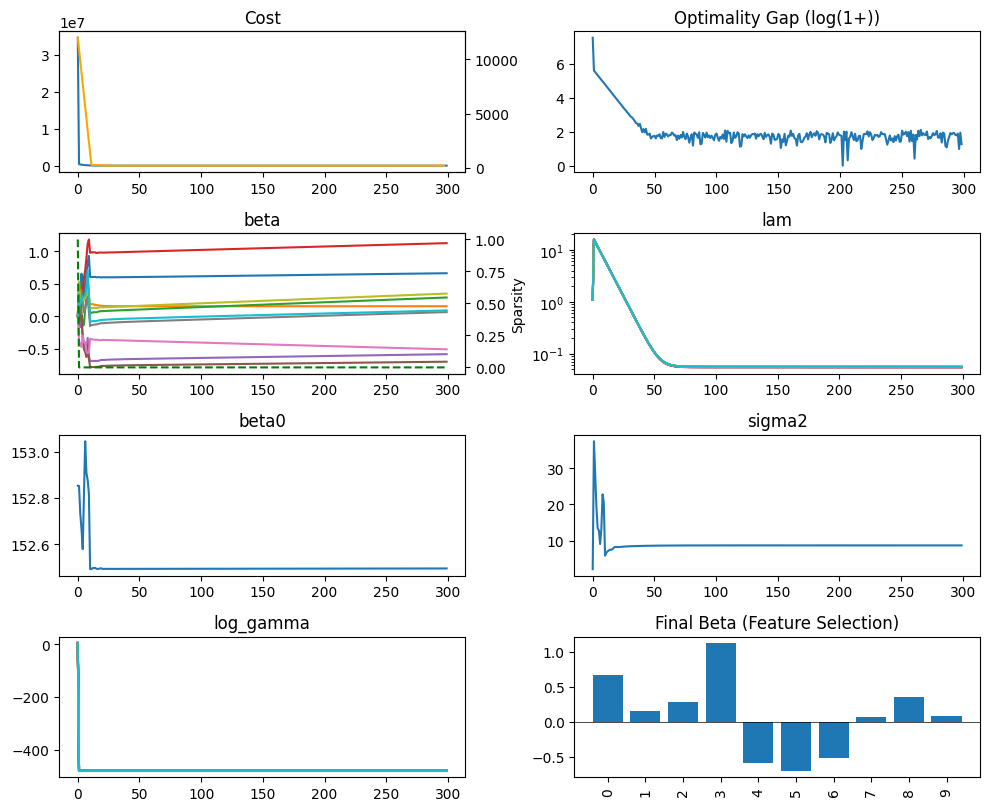

Testing max_iters=300, lr_pre=0.15
  MSE: 4949.5225, R²: 0.0348
  Coefficients: [-0.08712706 -0.11742236  1.04951127  1.83188884  0.13794713  0.
  0.30957333 -0.63901035  0.59437079  0.46883802]
  Number of nonzero coefficients: 9


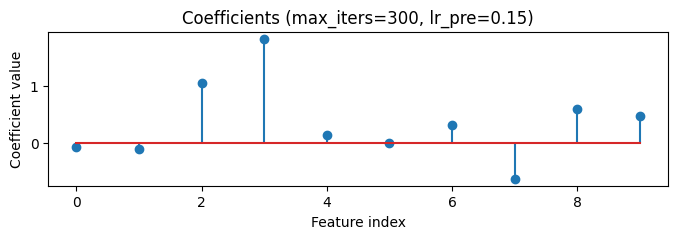

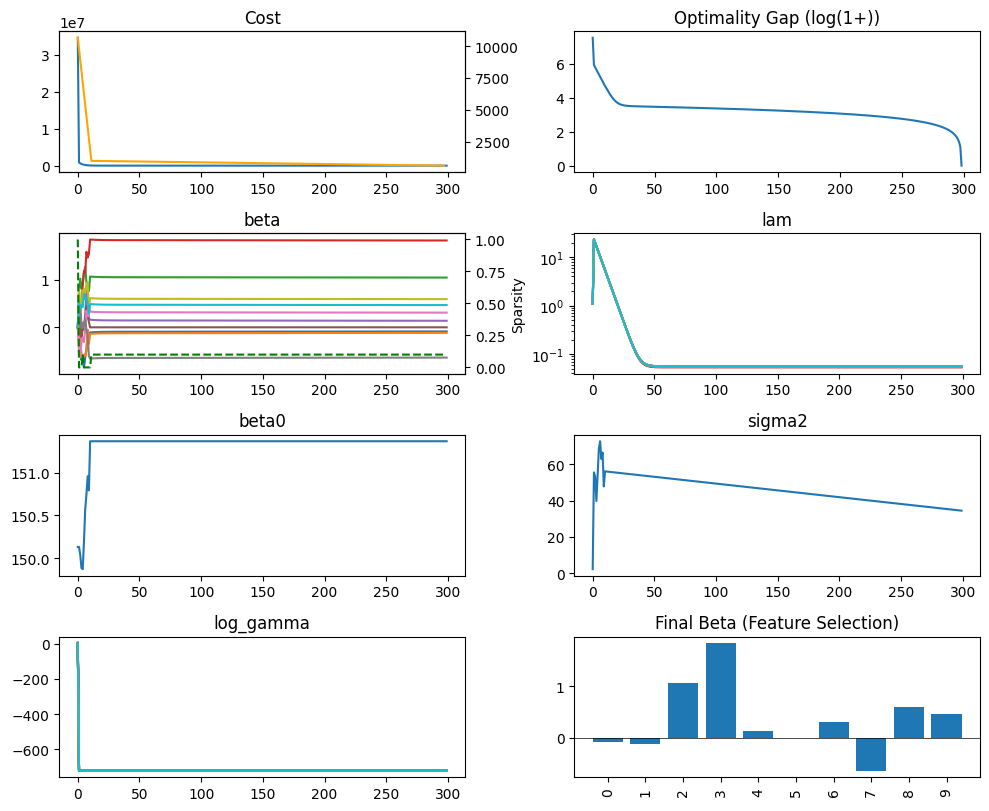

Testing max_iters=300, lr_pre=0.2
  MSE: 4583.7374, R²: 0.1061
  Coefficients: [ 0.0478995  -0.79574588  1.34758042  1.00254163  1.11211399 -0.0165309
 -0.86318046  0.98752377  3.73217559  3.12297243]
  Number of nonzero coefficients: 10


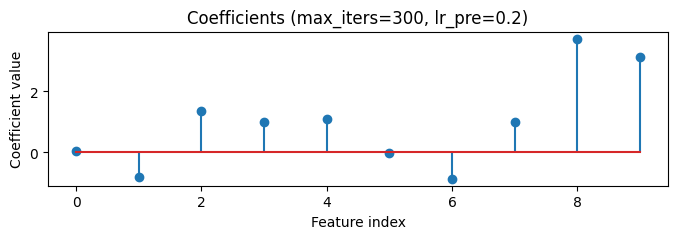

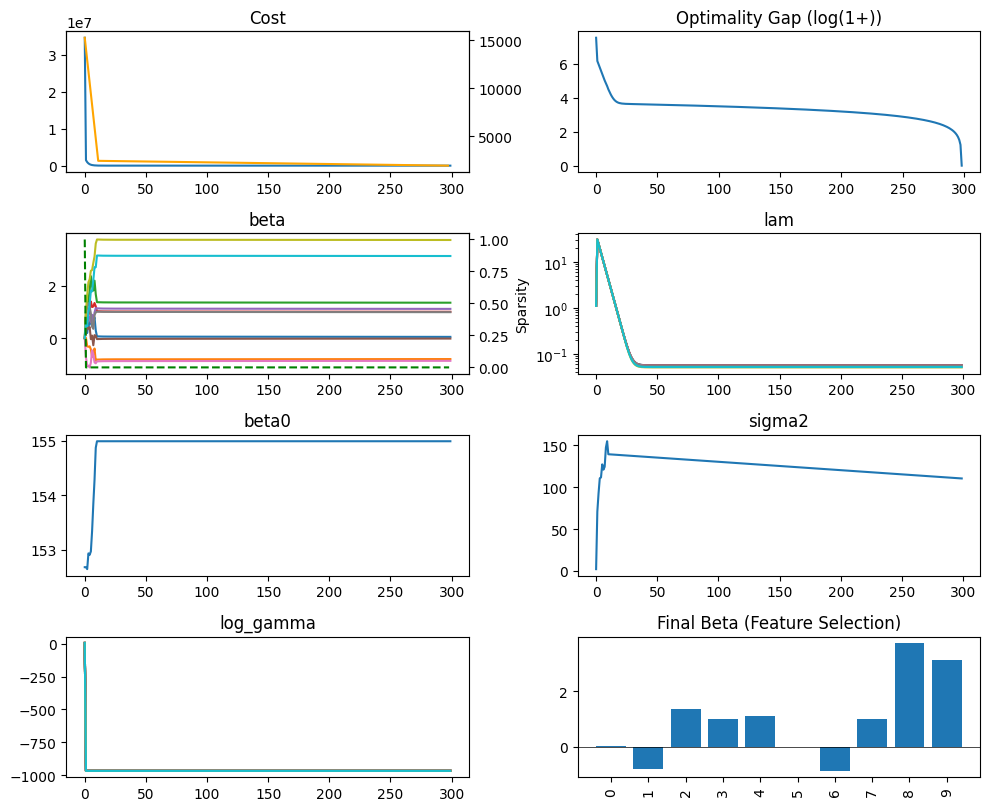

Testing max_iters=300, lr_pre=0.3
  MSE: 4623.3990, R²: 0.0984
  Coefficients: [-0.34032014 -0.21321605  2.23307248  0.57433039  2.3897408   1.80240896
 -0.98380428  1.82805103  3.02765471 -0.15444876]
  Number of nonzero coefficients: 10


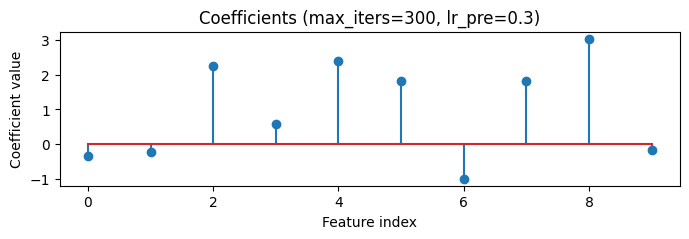

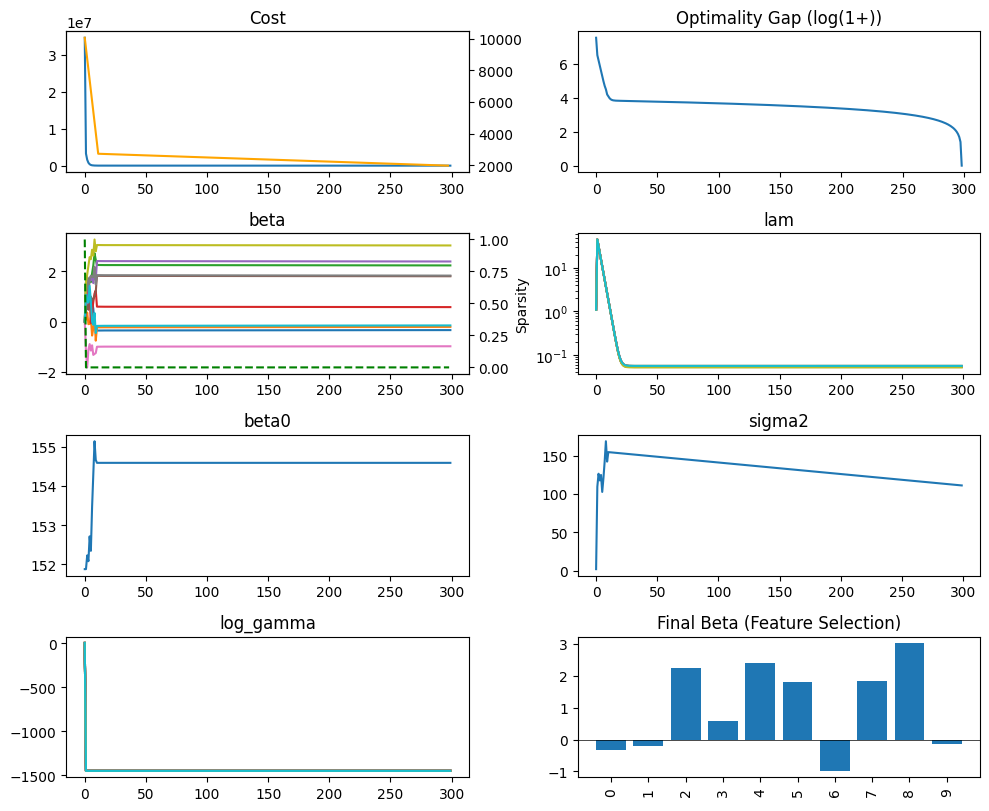

Testing max_iters=300, lr_pre=0.4
  MSE: 4576.7018, R²: 0.1075
  Coefficients: [ 0.33638878 -0.10131144  2.52021755  0.54599345 -0.47976527 -0.43821665
 -3.84367282  3.55068828  2.91927166  1.75803981]
  Number of nonzero coefficients: 10


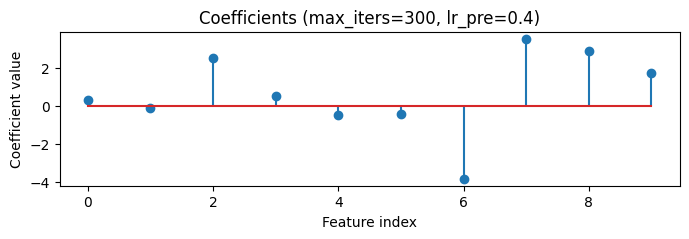

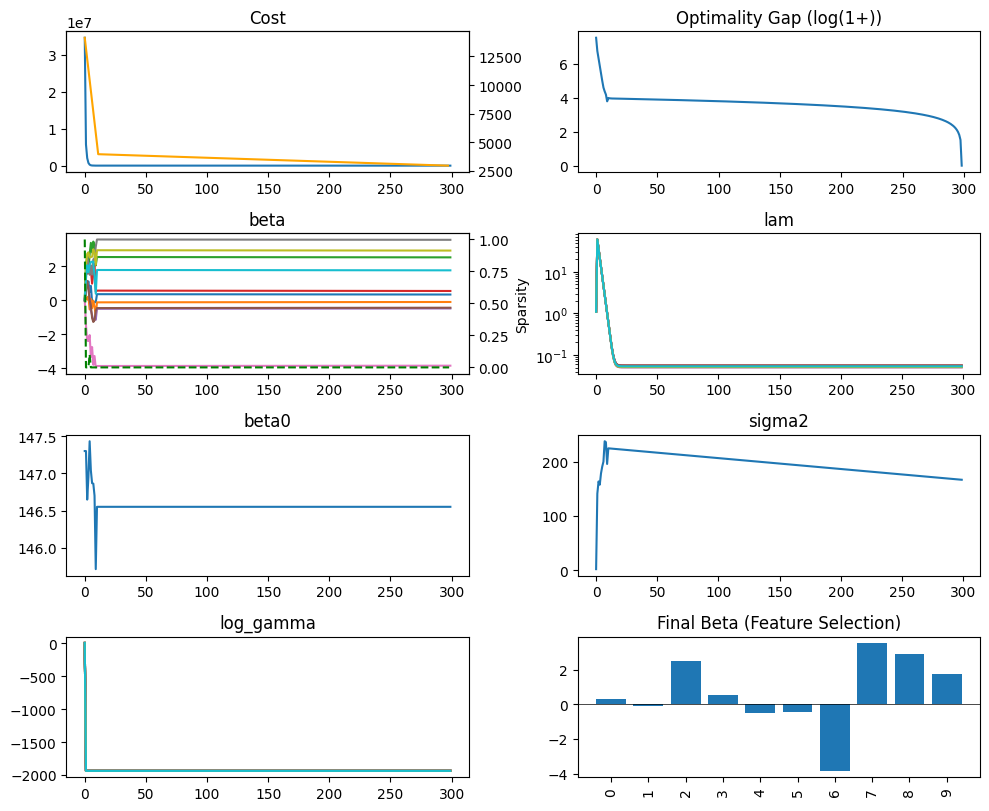

   max_iters  lr_pre          mse        r2
0        300  0.0005  5118.329773  0.001872
1        300  0.0010  5113.255566  0.002861
2        300  0.0100  5116.193373  0.002288
3        300  0.1000  5025.267153  0.020020
4        300  0.1500  4949.522488  0.034791
5        300  0.2000  4583.737352  0.106123
6        300  0.3000  4623.398988  0.098388
7        300  0.4000  4576.701781  0.107495


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from adaptivelasso.skcompat import MAPAdaptiveLasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.datasets import load_diabetes
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np

# Define parameter grids
max_iters_list = [300] # [300, 1000, 3000, 5000, 10000]
lr_pre_list = [0.0005, 0.001, 0.01, 0.1, 0.15, 0.2, 0.3, 0.4]

# Prepate data
data = load_diabetes()
X = data.data
y = data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

results = []
for max_iters in max_iters_list:
    for lr_pre in lr_pre_list:
        print(f"Testing max_iters={max_iters}, lr_pre={lr_pre}")
        pipe = Pipeline([
            ('scale', StandardScaler()),
            ('jax_model', MAPAdaptiveLasso(
                lam_prior='hier',
                lik='normal',
                max_iters=max_iters,
                lr_pre=lr_pre,
                track=True,
                mb_size=30,
                lam_prior_vars = {'log_gamma': np.full(X_synthetic.shape[1], 5.0)}
            ))
        ])
        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)
        mse = mean_squared_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)
        print(f"  MSE: {mse:.4f}, R²: {r2:.4f}")

        # Print coefficients
        coefs = pipe.named_steps['jax_model'].model_.vv['beta']
        print("  Coefficients:", coefs)
        print("  Number of nonzero coefficients:", np.sum(np.abs(coefs) > 1e-6))

        # Plot coefficients
        plt.figure(figsize=(8, 2))
        plt.stem(coefs)
        plt.title(f"Coefficients (max_iters={max_iters}, lr_pre={lr_pre})")
        plt.xlabel("Feature index")
        plt.ylabel("Coefficient value")
        plt.show()
        pipe.named_steps["jax_model"].model_.plot()

        results.append({'max_iters': max_iters, 'lr_pre': lr_pre, 'mse': mse, 'r2': r2})

# Optionally, display all results as a table
import pandas as pd
print(pd.DataFrame(results))

In [4]:
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error

# LassoCV testing
lasso_cv = LassoCV(cv=5, random_state=0, max_iter=3000)
lasso_cv.fit(X_train, y_train)

y_pred_lasso = lasso_cv.predict(X_test)

rmse_lasso = mean_squared_error(y_test, y_pred_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print("===== LassoCV Results =====")
print("Best alpha:", lasso_cv.alpha_)
print("Test RMSE:", rmse_lasso)
print("Test R²:", r2_lasso)
print("Estimated coefficients:", lasso_cv.coef_)

===== LassoCV Results =====
Best alpha: 0.4173779421288694
Test RMSE: 3435.5342812382155
Test R²: 0.3300344834216907
Estimated coefficients: [ -0.94727812 -10.74389633  27.74231615  13.531308   -10.50667539
  -0.          -8.51902342   3.66178658  28.07857011   1.84131351]
